Загрузка данных для EDA...

=== ОСНОВНЫЕ ХАРАКТЕРИСТИКИ (ТОП-10 ВАЖНЫХ ЧИСЛОВЫХ ПРИЗНАКОВ) ===
                  mean     std    min   25%  median     75%       max
TransactionAmt   79.40   53.66   0.25  39.0    59.0  107.95    247.77
dist1            50.82  236.15   0.00   8.0     8.0    8.00  10286.00
dist2            53.11  145.59   0.00  40.0    40.0   40.00  11623.00
C1               14.81  138.30   0.00   1.0     1.0    3.00   4685.00
C2               16.12  160.39   0.00   1.0     1.0    3.00   5691.00
C13              34.45  133.75   0.00   1.0     3.0   13.00   2918.00
D1               96.32  158.47   0.00   0.0     5.0  127.00    640.00
D10             112.59  175.14   0.00   0.0    19.0  156.00    876.00
D15             150.98  191.56 -83.00   0.0    58.0  260.00    879.00
V1                1.00    0.01   0.00   1.0     1.0    1.00      1.00

Строим гистограммы...


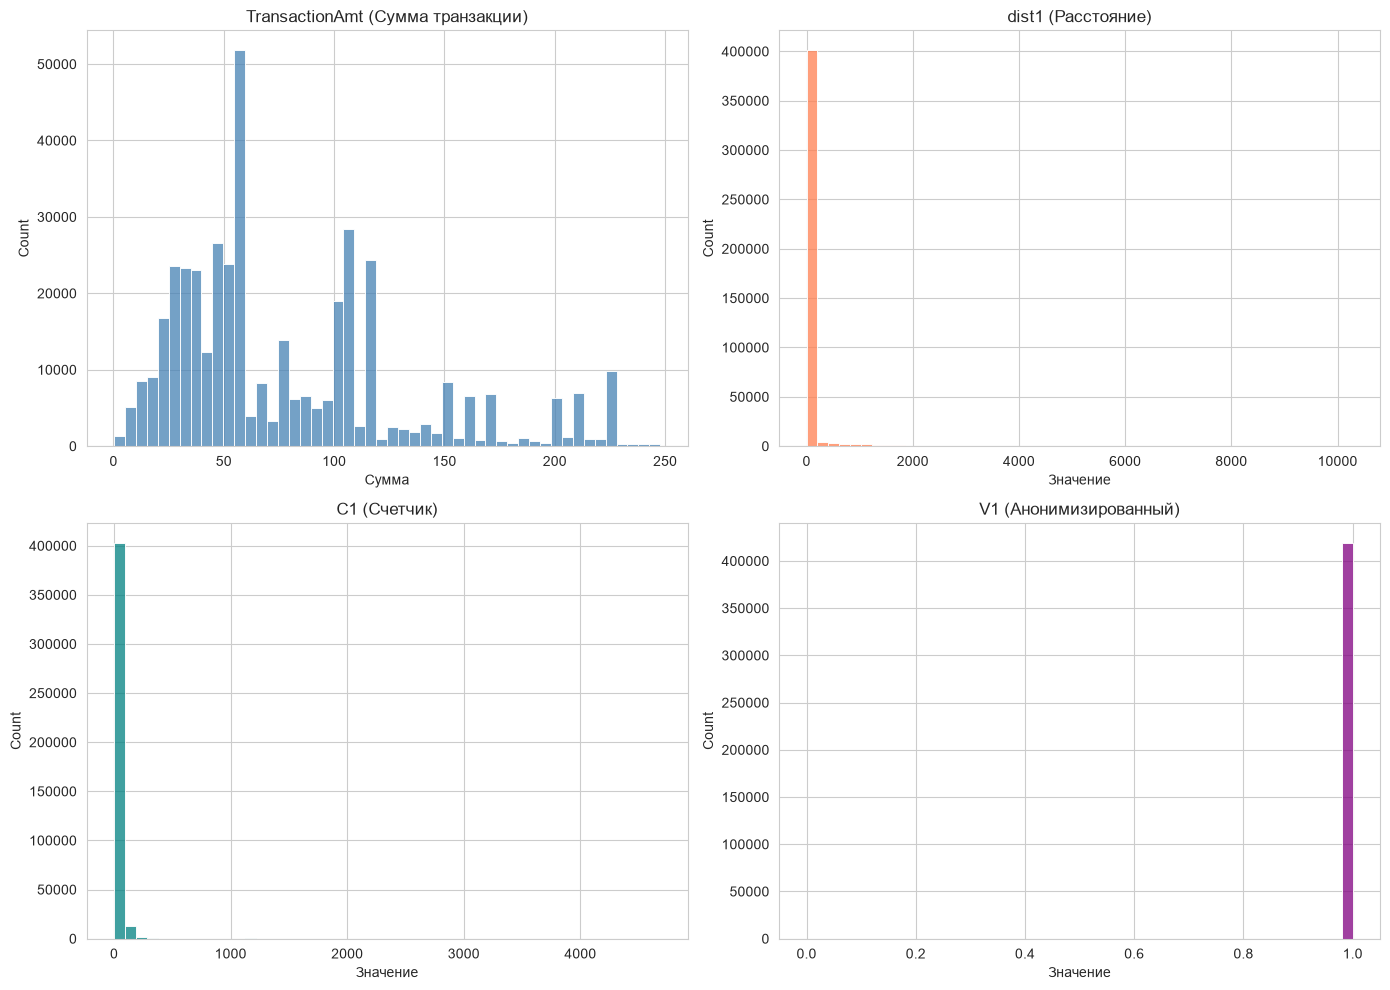


Строим дисбаланс классов...


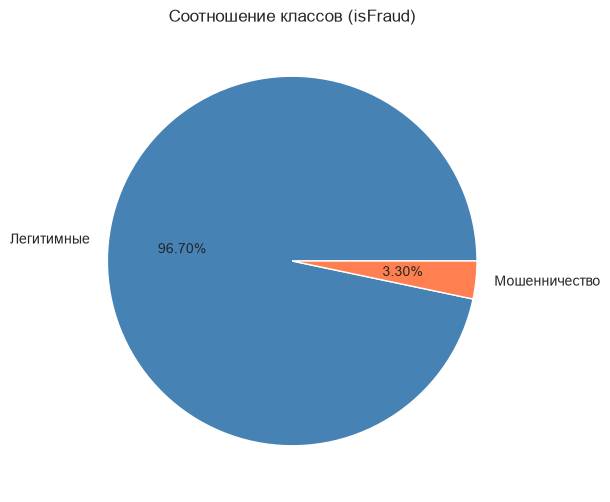


Загрузка отфильтрованных данных...
Считаем корреляцию с таргетом (только для отобранных признаков)...

Топ-20 отфильтрованных признаков по корреляции с isFraud:
V242    0.342
V246    0.329
V257    0.327
V186    0.326
V187    0.325
V244    0.324
V243    0.321
V258    0.319
V190    0.313
V199    0.302
V232    0.286
V217    0.259
V219    0.255
V218    0.245
V228    0.242
V230    0.241
V178    0.240
V201    0.228
V229    0.227
V167    0.220
Name: isFraud, dtype: float64


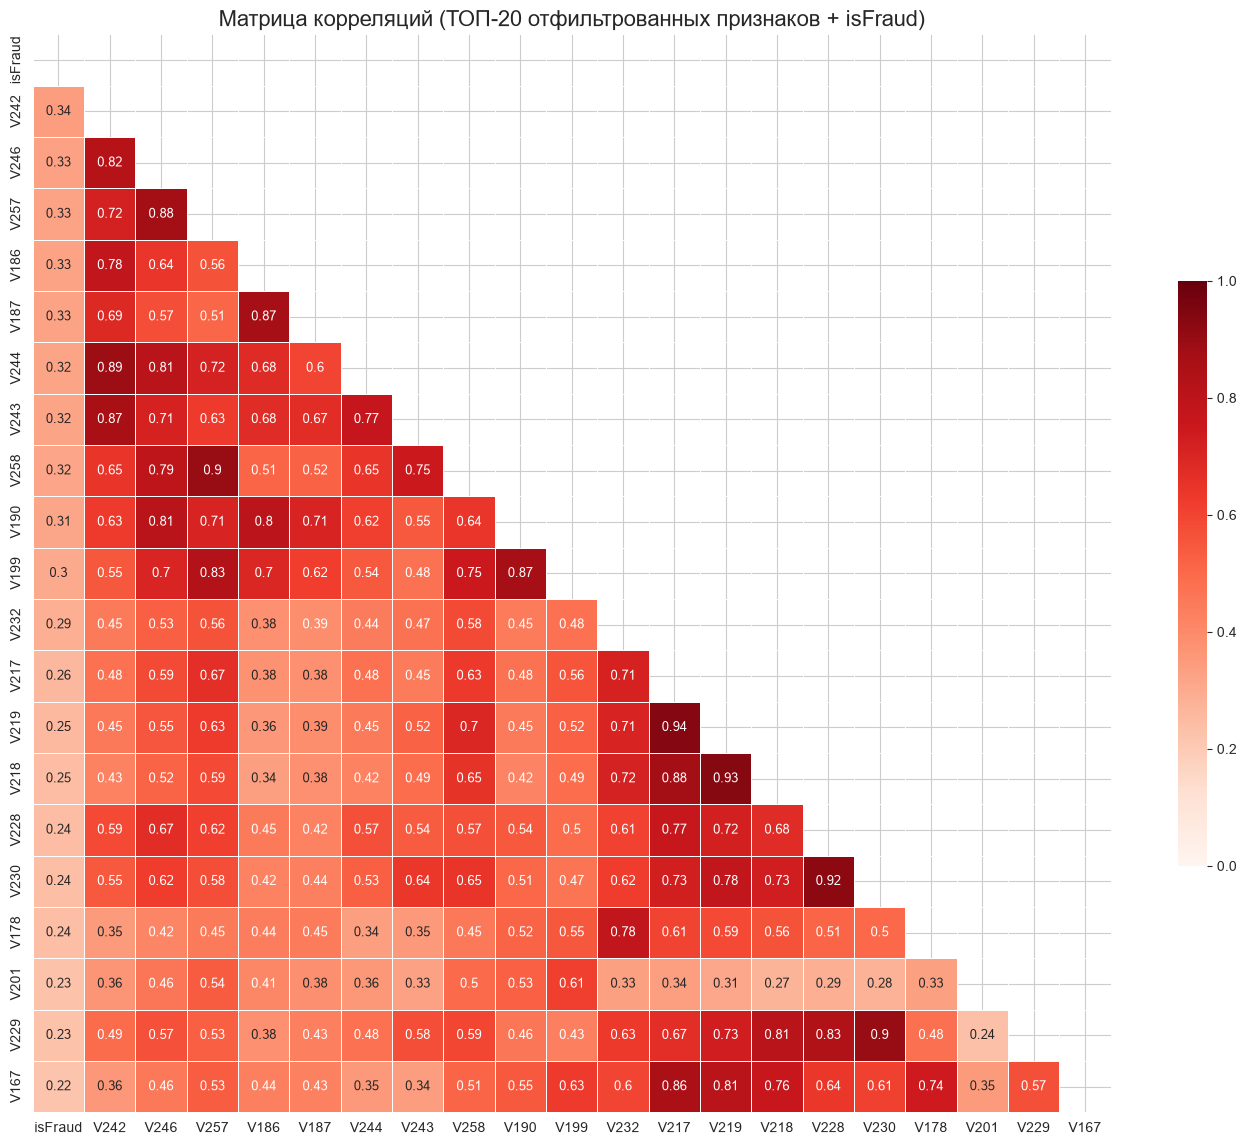


✅ Все графики сохранены в папку data/clean/


NameError: name 'df_sample' is not defined

In [1]:
# %% ============================================================
# 3. ВИЗУАЛИЗАЦИЯ И ОСНОВНЫЕ ХАРАКТЕРИСТИКИ (EDA)
# ============================================================
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

# --- ПУТИ ---
BASE_DIR = Path(r"C:\Users\egor0\ProjectsVSCode\ML_Practice")
DATA_DIR = BASE_DIR / "data"
CLEAN_DIR = DATA_DIR / "clean"
ENGINE = 'fastparquet'

print("Загрузка данных для EDA...")
df = pd.read_parquet(CLEAN_DIR / 'train_part.parquet', engine=ENGINE)

# Списки категориальных признаков
cat_cols = [
    'ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain',
    'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9',
    'DeviceType', 'DeviceInfo', 
    'id_12', 'id_15', 'id_16', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 
    'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 
    'id_36', 'id_37', 'id_38'
]

# ============================================================
# 3.1. ОСНОВНЫЕ ХАРАКТЕРИСТИКИ (describe)
# ============================================================
print("\n=== ОСНОВНЫЕ ХАРАКТЕРИСТИКИ (ТОП-10 ВАЖНЫХ ЧИСЛОВЫХ ПРИЗНАКОВ) ===")
# Берем самые понятные признаки для отчета
key_cols = ['TransactionAmt', 'dist1', 'dist2', 'C1', 'C2', 'C13', 'D1', 'D10', 'D15', 'V1']

# Выводим базовую статистику: среднее, std, min, 25%, 50%, 75%, max
stats = df[key_cols].describe().T
stats['median'] = df[key_cols].median()  # Медиана (важна при выбросах)
print(stats[['mean', 'std', 'min', '25%', 'median', '75%', 'max']].round(2))

# ============================================================
# 3.2. РАСПРЕДЕЛЕНИЯ (ГИСТОГРАММЫ)
# ============================================================
print("\nСтроим гистограммы...")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Сумма транзакции
sns.histplot(df['TransactionAmt'], bins=50, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('TransactionAmt (Сумма транзакции)')
axes[0, 0].set_xlabel('Сумма')

# 2. Расстояние dist1
sns.histplot(df['dist1'].dropna(), bins=50, ax=axes[0, 1], color='coral')
axes[0, 1].set_title('dist1 (Расстояние)')
axes[0, 1].set_xlabel('Значение')

# 3. Признак C1 (счетчик)
sns.histplot(df['C1'].dropna(), bins=50, ax=axes[1, 0], color='teal')
axes[1, 0].set_title('C1 (Счетчик)')
axes[1, 0].set_xlabel('Значение')

# 4. Признак V1
sns.histplot(df['V1'].dropna(), bins=50, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('V1 (Анонимизированный)')
axes[1, 1].set_xlabel('Значение')

plt.tight_layout()
plt.savefig(CLEAN_DIR / 'histograms.png', dpi=150)
plt.show()

# ============================================================
# 3.3. ДИСБАЛАНС КЛАССОВ (ЦЕЛЕВАЯ ПЕРЕМЕННАЯ)
# ============================================================
print("\nСтроим дисбаланс классов...")
plt.figure(figsize=(6, 6))
df['isFraud'].value_counts().plot(kind='pie', autopct='%1.2f%%', 
                                  labels=['Легитимные', 'Мошенничество'],
                                  colors=['steelblue', 'coral'])
plt.title('Соотношение классов (isFraud)')
plt.ylabel('')
plt.savefig(CLEAN_DIR / 'class_imbalance.png', dpi=150)
plt.show()

# ============================================================
# 3.4. КОРРЕЛЯЦИОННАЯ МАТРИЦА (ТОП-20 ИЗ ОТФИЛЬТРОВАННЫХ)
# ============================================================
print("\nЗагрузка отфильтрованных данных...")
# Читаем файл, где остались только 214 числовых + 14 категориальных (после Спирмена)
df_filtered = pd.read_parquet(CLEAN_DIR / 'train_filtered.parquet', engine=ENGINE)

# Выделяем числовые колонки (исключаем категориальные и таргет)
cat_cols = [
    'ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain',
    'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9',
    'DeviceType', 'DeviceInfo', 
    'id_12', 'id_15', 'id_16', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 
    'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 
    'id_36', 'id_37', 'id_38'
]
num_cols_filtered = [c for c in df_filtered.columns if c not in cat_cols and c not in ['isFraud', 'TransactionID']]

# Берем подвыборку
df_sample = df_filtered.sample(n=min(10000, len(df_filtered)), random_state=42)

# 1. Считаем корреляцию ВСЕХ ОТФИЛЬТРОВАННЫХ признаков с таргетом
print("Считаем корреляцию с таргетом (только для отобранных признаков)...")
target_corr = df_sample[num_cols_filtered + ['isFraud']].corr(method='spearman')['isFraud'].abs().drop('isFraud', errors='ignore')

# 2. Берем ТОП-20
top_20_features = target_corr.sort_values(ascending=False).head(20).index.tolist()

print(f"\nТоп-20 отфильтрованных признаков по корреляции с isFraud:")
print(target_corr.sort_values(ascending=False).head(20).round(3))

# 3. Формируем список для матрицы
cols_for_matrix = ['isFraud'] + top_20_features

# 4. Считаем матрицу
corr_matrix = df_sample[cols_for_matrix].corr(method='spearman').abs()

# 5. Строим график
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
annot_data = np.where(mask, "", np.round(corr_matrix.values, 2))

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='Reds', 
    vmin=0, vmax=1, 
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": .5}, 
    annot=annot_data, 
    fmt="", 
    annot_kws={"size": 9}
)
plt.title('Матрица корреляций (ТОП-20 отфильтрованных признаков + isFraud)', fontsize=16)
plt.tight_layout()
plt.savefig(CLEAN_DIR / 'correlation_matrix_filtered_top20.png', dpi=150)
plt.show()

del df_filtered, df_sample
gc.collect()

print("\n✅ Все графики сохранены в папку data/clean/")
del df, df_sample
gc.collect()